# Instrument Response Downloader

This is a notebook for downloading instrument spectral response files from the [SVO Filter Profile Service](https://svo2.cab.inta-csic.es/theory/fps3/index.php?mode=voservice), and preparing them into csv files suitable for the VRDR resampler software.

Overview:
1. Define the downloader recipes
2. Define the data collection and csv writeout method
3. Run on: MEX HRSC, MRO HiRISE.

# SVO Downloader

In [1]:
# from Claude

import io
import re
from pathlib import Path

import pandas as pd
import requests
from astropy.io.votable import parse

SVO_FPS = "https://svo2.cab.inta-csic.es/theory/fps3/fps.php"


def _safe(name):
    return re.sub(r"[^\w.\-]+", "_", name)


def _col(df, name):
    """Case-insensitive column lookup."""
    for c in df.columns:
        if c.lower() == name.lower():
            return c
    raise KeyError(f"No '{name}' column in {list(df.columns)}")


def _transmission_table(votable):
    """Return the table in a filter VOTable that holds wavelength/transmission."""
    for table in votable.iter_tables():
        names = {f.name.lower() for f in table.fields}
        if {"wavelength", "transmission"} <= names:
            df = table.to_table().to_pandas()
            return df.rename(columns={_col(df, "Wavelength"): "wavelength_AA",
                                      _col(df, "Transmission"): "transmission"})
    raise ValueError("No transmission curve found in VOTable")


def download_svo_instrument(instrument, facility=None, outdir="./svo_profiles"):
    """Download all SVO FPS filter transmission curves for one instrument.

    Writes one CSV per filter (wavelength_AA, transmission) plus an
    index CSV holding the SVO metadata for each filter.
    """
    outdir = Path(outdir, instrument)
    outdir.mkdir(parents=True, exist_ok=True)

    # 1. Search by instrument (VERB=0: properties only, no curves -> fast)
    params = {"Instrument": instrument, "VERB": 0}
    if facility:
        params["Facility"] = facility
    r = requests.get(SVO_FPS, params=params, timeout=60)
    r.raise_for_status()
    meta = parse(io.BytesIO(r.content)).get_first_table().to_table().to_pandas()

    if meta.empty:
        raise ValueError(f"No filters found in SVO for instrument '{instrument}'")

    # 2. Fetch each filter by ID (default verbosity includes the curve)
    id_col = _col(meta, "filterID")
    saved = []
    for filter_id in meta[id_col]:
        filter_id = str(filter_id)
        r = requests.get(SVO_FPS, params={"ID": filter_id}, timeout=60)
        r.raise_for_status()
        curve = _transmission_table(parse(io.BytesIO(r.content)))
        fname = _safe(filter_id) + ".csv"
        curve[["wavelength_AA", "transmission"]].to_csv(outdir / fname, index=False)
        saved.append(fname)
        print(f"{filter_id:<40s} {len(curve):5d} points -> {fname}")

    # 3. Metadata index alongside the profiles
    meta["csv_file"] = saved
    meta.to_csv(outdir / f"{_safe(instrument)}_index.csv", index=False)
    return meta

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd


def combine_svo_profiles(indir="./svo_profiles", outfile=None, grid_step=None, wavelength_unit="nm"):
    """Combine per-filter CSVs into one CSV on a common wavelength grid.

    Each filter is linearly interpolated onto the grid within its own
    wavelength range and set to 0 outside it (no extrapolation).

    grid_step : None -> grid is the union of every native wavelength sample
                         (no information lost, irregular spacing)
                float -> regular grid in Å from the global min to max
    """
    indir = Path(indir)
    outfile = Path(outfile) if outfile else Path("./instrument_response") / f"{indir.stem}.csv"

    # Per-filter files only: skip the index CSV and any previous combined output
    files = sorted(f for f in indir.glob("*.csv")
                   if not f.name.endswith("_index.csv") and f != outfile)
    if not files:
        raise FileNotFoundError(f"No filter CSVs found in {indir}")

    curves = {}
    for f in files:
        df = pd.read_csv(f)
        # sort by wavelength and average any duplicated wavelength samples
        df = df.groupby("wavelength_AA", as_index=False)["transmission"].mean()
        curves[f.stem] = df

    # Common wavelength grid
    if grid_step is None:
        grid = np.unique(np.concatenate([c["wavelength_AA"].to_numpy()
                                         for c in curves.values()]))
    else:
        lo = min(c["wavelength_AA"].min() for c in curves.values())
        hi = max(c["wavelength_AA"].max() for c in curves.values())
        grid = np.arange(lo, hi + grid_step, grid_step)

    # Linear interpolation per filter; zero outside the filter's own range
    combined = pd.DataFrame({f"wvls": grid})
    for name, c in curves.items():
        if wavelength_unit == "nm":            
            grid_nm = grid / 10.0  # convert Å to nm
            combined[name] = np.interp(grid_nm, c["wavelength_AA"] / 10.0, c["transmission"],
                                       left=0.0, right=0.0)
            # change grid in combined to grid_nm
            combined[f"wvls"] = grid_nm
        else:
            combined[name] = np.interp(grid, c["wavelength_AA"], c["transmission"],
                                       left=0.0, right=0.0)

    combined.to_csv(outfile, index=False)
    print(f"{len(curves)} filters, {len(grid)} wavelength samples -> {outfile}")

    return combined


In [7]:
def collect_instrument_response(instrument_name, facility_name=None):
    
    index = download_svo_instrument(instrument_name, facility_name)
    index.head()

    combined = combine_svo_profiles(f"./svo_profiles/{instrument_name}")            # native-sample union grid
    combined.head()

    combined.plot(x="wavelength_nm", y=combined.columns[1:])

ExoMars/CaSSIS.Blue_fil                    198 points -> ExoMars_CaSSIS.Blue_fil.csv
ExoMars/CaSSIS.Blue                        200 points -> ExoMars_CaSSIS.Blue.csv
ExoMars/CaSSIS.Pan_fil                     198 points -> ExoMars_CaSSIS.Pan_fil.csv
ExoMars/CaSSIS.Pan                         199 points -> ExoMars_CaSSIS.Pan.csv
ExoMars/CaSSIS.Red                         200 points -> ExoMars_CaSSIS.Red.csv
ExoMars/CaSSIS.Red_fil                     197 points -> ExoMars_CaSSIS.Red_fil.csv
ExoMars/CaSSIS.NIR                         200 points -> ExoMars_CaSSIS.NIR.csv
ExoMars/CaSSIS.NIR_fil                     199 points -> ExoMars_CaSSIS.NIR_fil.csv
8 filters, 1591 wavelength samples -> instrument_response/CaSSIS.csv


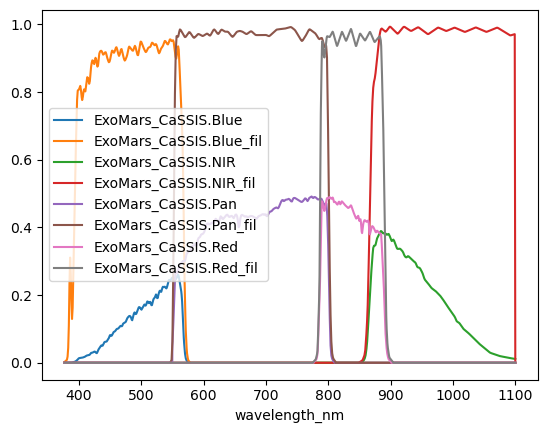

In [8]:
instrument_name = "CaSSIS"   # <- SVO instrument name
facility_name = None         # optionally e.g. "TGO" to disambiguate

collect_instrument_response(instrument_name, facility_name)

MEX/HRSC.Blue                              200 points -> MEX_HRSC.Blue.csv
MEX/HRSC.Green                             200 points -> MEX_HRSC.Green.csv
MEX/HRSC.P12                               200 points -> MEX_HRSC.P12.csv
MEX/HRSC.S1                                200 points -> MEX_HRSC.S1.csv
MEX/HRSC.ND                                200 points -> MEX_HRSC.ND.csv
MEX/HRSC.S2                                200 points -> MEX_HRSC.S2.csv
MEX/HRSC.Red                               200 points -> MEX_HRSC.Red.csv
MEX/HRSC.NIR                               200 points -> MEX_HRSC.NIR.csv
8 filters, 1199 wavelength samples -> instrument_response/HRSC.csv


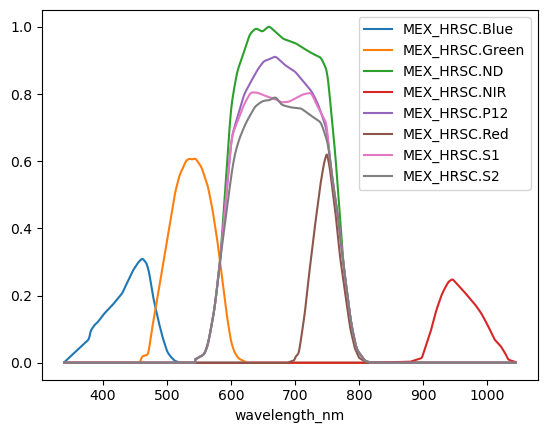

In [9]:
instrument_name = "HRSC"   # <- SVO instrument name
facility_name = None         # optionally e.g. "TGO" to disambiguate

collect_instrument_response(instrument_name, facility_name)

MRO/HiRISE.BG                              200 points -> MRO_HiRISE.BG.csv
MRO/HiRISE.Red                             200 points -> MRO_HiRISE.Red.csv
MRO/HiRISE.NIR                             200 points -> MRO_HiRISE.NIR.csv
3 filters, 600 wavelength samples -> instrument_response/HiRISE.csv


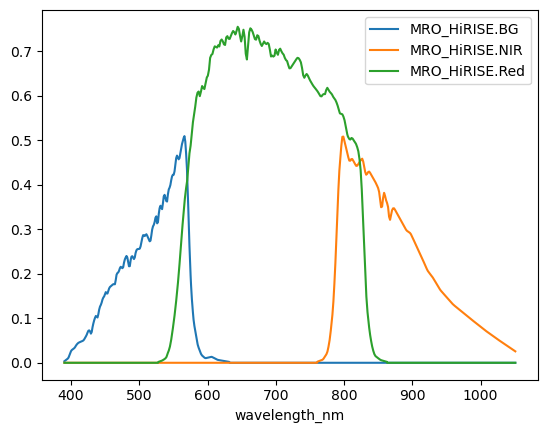

In [10]:
instrument_name = "HiRISE"   # <- SVO instrument name
facility_name = None         # optionally e.g. "TGO" to disambiguate

collect_instrument_response(instrument_name, facility_name)